
# Airbnb New York City — Final Data Analysis Project

## Project Overview

This project analyzes the Airbnb listings dataset provided for New York City.

The objective is to understand listing distribution, room types, pricing patterns, geographical differences, review activity, and availability.

The project follows a complete data analysis workflow:
1. Data understanding
2. Data quality assessment
3. Data cleaning and preparation
4. Exploratory data analysis
5. Data visualization
6. Business insights and recommendations

## Data Source

AB_NYC_2019.csv — the dataset attached to the final task.

## Tools

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook
- Power BI

# 1-Data Understanding

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the original dataset
df = pd.read_csv("dataset/AB_NYC_2019.csv")

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Inspect data types and missing values
df.info()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


Number of rows: 48895
Number of columns: 16

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude              

In [2]:
# Missing values by column
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

display(missing[missing["Missing_Count"] > 0]
        .sort_values("Missing_Count", ascending=False))

# Duplicate checks
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate listing IDs:", df["id"].duplicated().sum())

# Unique values in categorical columns
for col in ["neighbourhood_group", "room_type"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

# Numerical summary
display(df.describe().T)

,Missing_Count,Missing_Percentage
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03


Duplicate rows: 0
Duplicate listing IDs: 0

neighbourhood_group:
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

room_type:
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


# 2-Data Cleaning 

In [3]:
# Keep the original dataset unchanged
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original shape: (48895, 16)
Working copy shape: (48895, 16)


In [4]:
# Check whether missing review information is associated with listings that have no reviews

print("Listings with zero reviews:",
      (df_clean["number_of_reviews"] == 0).sum())

print("\nMissing reviews_per_month among zero-review listings:",
      df_clean.loc[
          df_clean["number_of_reviews"] == 0,
          "reviews_per_month"
      ].isna().sum())

print("\nMissing reviews_per_month among listings with reviews:",
      df_clean.loc[
          df_clean["number_of_reviews"] > 0,
          "reviews_per_month"
      ].isna().sum())

Listings with zero reviews: 10052

Missing reviews_per_month among zero-review listings: 10052

Missing reviews_per_month among listings with reviews: 0


In [5]:
# Convert last_review to a proper date
df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

# Ensure numeric fields are numeric
numeric_columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "latitude",
    "longitude",
    "calculated_host_listings_count",
    "availability_365"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print(df_clean.dtypes)

id                                         int64
name                                      object
host_id                                    int64
host_name                                 object
neighbourhood_group                       object
neighbourhood                             object
latitude                                 float64
longitude                                float64
room_type                                 object
price                                      int64
minimum_nights                             int64
number_of_reviews                          int64
last_review                       datetime64[ns]
reviews_per_month                        float64
calculated_host_listings_count             int64
availability_365                           int64
dtype: object


In [6]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate IDs:", df_clean["id"].duplicated().sum())

print("Zero-price listings:",
      (df_clean["price"] == 0).sum())

print("Prices below zero:",
      (df_clean["price"] < 0).sum())

print("Minimum nights below 1:",
      (df_clean["minimum_nights"] < 1).sum())

print("Availability outside 0-365:",
      (~df_clean["availability_365"].between(0, 365)).sum())

print("Review counts below zero:",
      (df_clean["number_of_reviews"] < 0).sum())

Duplicate rows: 0
Duplicate IDs: 0
Zero-price listings: 11
Prices below zero: 0
Minimum nights below 1: 0
Availability outside 0-365: 0
Review counts below zero: 0


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
90%        269.000000
95%        355.000000
99%        799.000000
max      10000.000000
Name: price, dtype: float64

count    48895.000000
mean         7.029962
std         20.510550
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
90%         28.000000
95%         30.000000
99%         45.000000
max       1250.000000
Name: minimum_nights, dtype: float64

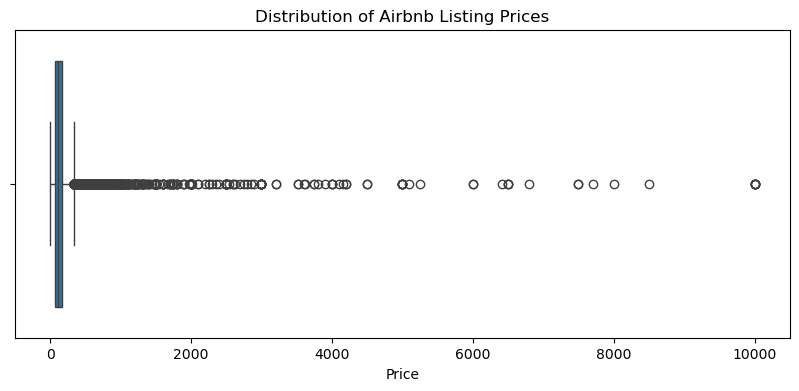

In [7]:
# Inspect price distribution
display(
    df_clean["price"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Inspect minimum-night distribution
display(
    df_clean["minimum_nights"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Visualize price outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_clean["price"])
plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price")
plt.show()

In [8]:
# Price validity flag
df_clean["price_valid"] = df_clean["price"] > 0

# Review activity flag
df_clean["has_reviews"] = df_clean["number_of_reviews"] > 0

# Extract date components when a review date exists
df_clean["last_review_year"] = (
    df_clean["last_review"].dt.year
)

df_clean["last_review_month"] = (
    df_clean["last_review"].dt.month
)

print(df_clean[
    ["price", "price_valid", "number_of_reviews",
     "has_reviews", "last_review_year", "last_review_month"]
].head())

   price  price_valid  number_of_reviews  has_reviews  last_review_year  \
0    149         True                  9         True            2018.0   
1    225         True                 45         True            2019.0   
2    150         True                  0        False               NaN   
3     89         True                270         True            2019.0   
4     80         True                  9         True            2018.0   

   last_review_month  
0               10.0  
1                5.0  
2                NaN  
3                7.0  
4               11.0  


In [9]:
# Fill missing monthly review counts with zero only because all missing values belong to listings with zero reviews

zero_review_mask = df_clean["number_of_reviews"] == 0

df_clean.loc[
    zero_review_mask & df_clean["reviews_per_month"].isna(),
    "reviews_per_month"
] = 0

print(
    "Missing reviews_per_month after cleaning:",
    df_clean["reviews_per_month"].isna().sum()
)

print(
    "Listings with zero reviews:",
    (df_clean["number_of_reviews"] == 0).sum()
)

print(
    "Missing last_review dates:",
    df_clean["last_review"].isna().sum()
)

Missing reviews_per_month after cleaning: 0
Listings with zero reviews: 10052
Missing last_review dates: 10052


In [10]:
df_clean["name_display"] = (
    df_clean["name"].fillna("Unknown Listing")
)

df_clean["host_name_display"] = (
    df_clean["host_name"].fillna("Unknown Host")
)

print("Missing original names:", df_clean["name"].isna().sum())
print("Missing original host names:", df_clean["host_name"].isna().sum())

Missing original names: 16
Missing original host names: 21


In [11]:
# Flag zero and positive prices
df_clean["price_valid"] = df_clean["price"] > 0

# Flag unusually high prices using the IQR rule
q1 = df_clean["price"].quantile(0.25)
q3 = df_clean["price"].quantile(0.75)
iqr = q3 - q1

upper_price_limit = q3 + 1.5 * iqr

df_clean["price_outlier"] = (
    df_clean["price"] > upper_price_limit
)

# Flag unusually high minimum-night requirements
nights_q1 = df_clean["minimum_nights"].quantile(0.25)
nights_q3 = df_clean["minimum_nights"].quantile(0.75)
nights_iqr = nights_q3 - nights_q1

upper_nights_limit = nights_q3 + 1.5 * nights_iqr

df_clean["minimum_nights_outlier"] = (
    df_clean["minimum_nights"] > upper_nights_limit
)

print("Upper price outlier threshold:", upper_price_limit)
print("Flagged price outliers:", df_clean["price_outlier"].sum())

print("Upper minimum-nights threshold:", upper_nights_limit)
print(
    "Flagged minimum-nights outliers:",
    df_clean["minimum_nights_outlier"].sum()
)

Upper price outlier threshold: 334.0
Flagged price outliers: 2972
Upper minimum-nights threshold: 11.0
Flagged minimum-nights outliers: 6607


In [12]:
# Final quality checks
quality_report = pd.DataFrame({
    "Missing Values": df_clean.isna().sum(),
    "Missing Percentage": (
        df_clean.isna().mean() * 100
    ).round(2)
})

display(
    quality_report[
        quality_report["Missing Values"] > 0
    ]
)

print("Final rows:", len(df_clean))
print("Final columns:", len(df_clean.columns))
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate IDs:", df_clean["id"].duplicated().sum())


,Missing Values,Missing Percentage
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
last_review_year,10052,20.56
last_review_month,10052,20.56


Final rows: 48895
Final columns: 24
Duplicate rows: 0
Duplicate IDs: 0


# 3-EDA

,Listing Count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


,Percentage
room_type,
Entire home/apt,51.97
Private room,45.66
Shared room,2.37


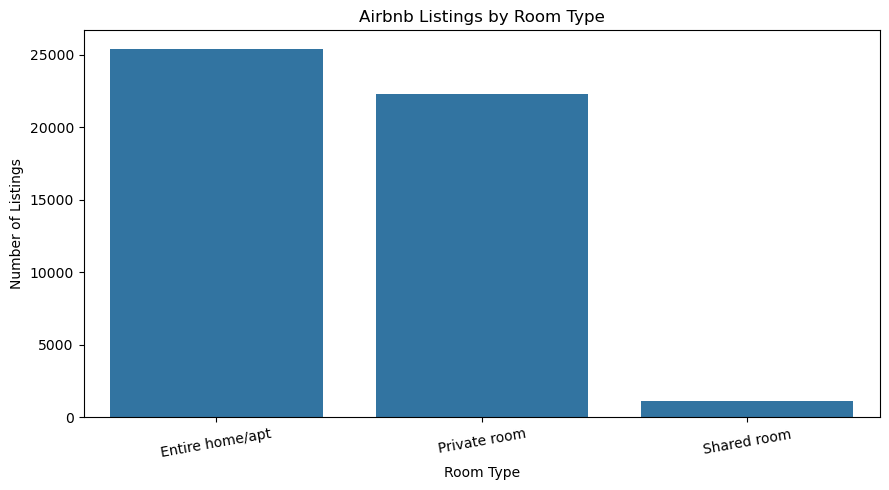

In [16]:

# Listing count by room type
room_counts = (
    df_clean.groupby("room_type")
    .size()
    .sort_values(ascending=False)
)

display(room_counts.rename("Listing Count").to_frame())

# Percentages
room_percentages = (
    df_clean["room_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(room_percentages.rename("Percentage").to_frame())

# Bar chart
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    x="room_type",
    order=df_clean["room_type"].value_counts().index
)
plt.title("Airbnb Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

,Area,Listing Count
0,Manhattan,21661
1,Brooklyn,20104
2,Queens,5666
3,Bronx,1091
4,Staten Island,373


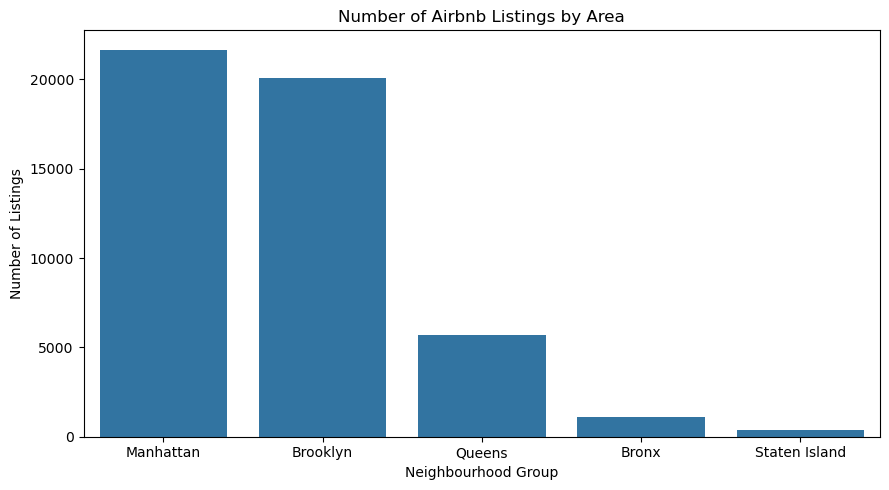

In [17]:

# Number of listings in each borough
area_counts = (
    df_clean["neighbourhood_group"]
    .value_counts()
    .rename_axis("Area")
    .reset_index(name="Listing Count")
)

display(area_counts)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=area_counts,
    x="Area",
    y="Listing Count"
)
plt.title("Number of Airbnb Listings by Area")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

In [18]:

top_neighbourhoods = (
    df_clean.groupby("neighbourhood")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Listing Count")
)

display(top_neighbourhoods)

,neighbourhood,Listing Count
0,Williamsburg,3920
1,Bedford-Stuyvesant,3714
2,Harlem,2658
3,Bushwick,2465
4,Upper West Side,1971
5,Hell's Kitchen,1958
6,East Village,1853
7,Upper East Side,1798
8,Crown Heights,1564
9,Midtown,1545


,count,mean,median
neighbourhood_group,,,
Manhattan,21660,196.88,150.0
Brooklyn,20095,124.44,90.0
Queens,5666,99.52,75.0
Staten Island,373,114.81,75.0
Bronx,1090,87.58,65.0


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100,54,40
Brooklyn,145,65,36
Manhattan,191,90,69
Queens,120,60,37
Staten Island,100,50,30


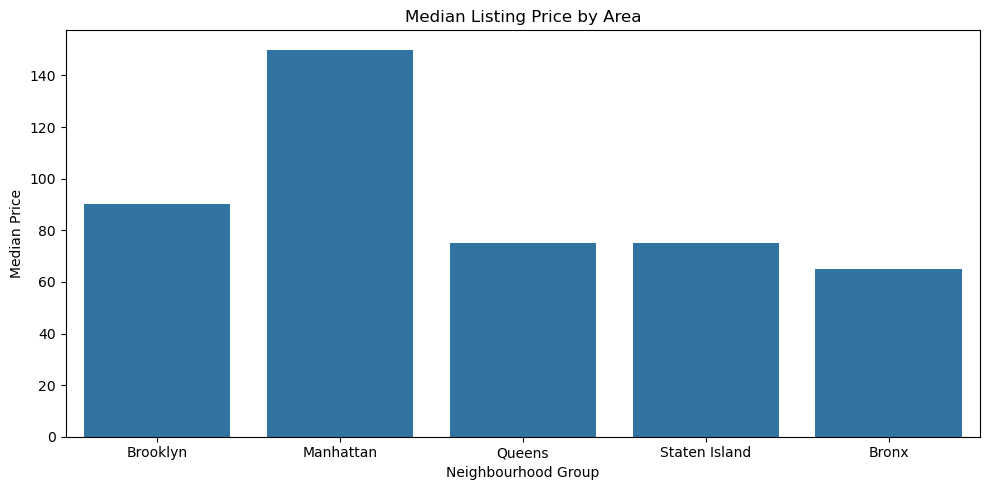

In [19]:

valid_prices = df_clean.loc[
    df_clean["price_valid"]
].copy()

# Average and median price by area
price_by_area = (
    valid_prices.groupby("neighbourhood_group")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(price_by_area)

# Median price by room type and area
price_matrix = valid_prices.pivot_table(
    index="neighbourhood_group",
    columns="room_type",
    values="price",
    aggfunc="median"
)

display(price_matrix.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=valid_prices,
    x="neighbourhood_group",
    y="price",
    estimator="median",
    errorbar=None
)
plt.title("Median Listing Price by Area")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Median Price")
plt.tight_layout()
plt.show()

In [20]:

# Median price by area and room type
area_room_price = (
    valid_prices.groupby(
        ["neighbourhood_group", "room_type"]
    )["price"]
    .median()
    .reset_index(name="Median Price")
)

display(area_room_price)

# Minimum nights by room type
nights_summary = (
    df_clean.groupby("room_type")["minimum_nights"]
    .agg(["median", "mean", "max"])
    .round(2)
)

display(nights_summary)

# Availability by room type
availability_summary = (
    df_clean.groupby("room_type")["availability_365"]
    .median()
    .sort_values(ascending=False)
)

display(availability_summary)

,neighbourhood_group,room_type,Median Price
0,Bronx,Entire home/apt,100.0
1,Bronx,Private room,54.0
2,Bronx,Shared room,40.0
3,Brooklyn,Entire home/apt,145.0
4,Brooklyn,Private room,65.0
5,Brooklyn,Shared room,36.0
6,Manhattan,Entire home/apt,191.0
7,Manhattan,Private room,90.0
8,Manhattan,Shared room,69.0
9,Queens,Entire home/apt,120.0


,median,mean,max
room_type,,,
Entire home/apt,3.0,8.51,1250
Private room,2.0,5.38,999
Shared room,1.0,6.48,999


room_type
Shared room        90.0
Private room       45.0
Entire home/apt    42.0
Name: availability_365, dtype: float64

In [21]:

# Hosts with the largest number of listings
host_counts = (
    df_clean.groupby("host_id")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("Listing Count")
    .reset_index()
)

display(host_counts)

,host_id,Listing Count
0,219517861,327
1,107434423,232
2,30283594,121
3,137358866,103
4,16098958,96
5,12243051,96
6,61391963,91
7,22541573,87
8,200380610,65
9,1475015,52


In [7]:
# Save a  CSV copy for Power BI
fixed_path = r"C:\Users\ThinkPad\Desktop\Internship_VOLTIX\Task_12\dataset\AB_NYC_CLEANED_FOR_POWERBI.csv"

check_df.to_csv(
    fixed_path,
    index=False,
    encoding="utf-8",
    quoting=1
)

print("Saved:", fixed_path)
print("Rows:", len(check_df))
print("Columns:", len(check_df.columns))
print("Unique IDs:", check_df["id"].nunique())

Saved: C:\Users\ThinkPad\Desktop\Internship_VOLTIX\Task_12\dataset\AB_NYC_CLEANED_FOR_POWERBI.csv
Rows: 48895
Columns: 24
Unique IDs: 48895
